In [2]:
import pandas as pd
import numpy as nd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

In [7]:
df = pd.read_csv(r"C:\Users\MT\Downloads\archive\ecommerce_sales_analytics_5000.csv")

In [13]:
print("Data set")
print(df.head())
print(f"Total Data : {df.shape[0]} Row and  {df.shape[1]} coloumn")

Data set
   order_id order_date  customer_id product_category region  quantity  \
0     10001   1/1/2022         1102           Beauty  South         7   
1     10002   1/2/2022         1435         Clothing  South         7   
2     10003   1/3/2022         1860           Beauty   East         3   
3     10004   1/4/2022         1270      Electronics   West         5   
4     10005   1/5/2022         1106         Clothing   West         5   

   unit_price  discount payment_method  delivery_days  customer_rating  \
0      373.65      0.28         Wallet             10              4.7   
1       47.74      0.09           Card              6              3.9   
2      311.28      0.31            COD              6              2.5   
3      524.47      0.02         Wallet              6              1.6   
4      139.87      0.33         Wallet              4              4.9   

   revenue  
0  1883.20  
1   304.10  
2   644.35  
3  2569.90  
4   468.56  
Total Data : 5000 Row and  12

In [15]:
df["order_date"] = pd.to_datetime(df["order_date"])
print("Basic Summary")
print(df.describe())

Basic Summary
           order_id           order_date  customer_id     quantity  \
count   5000.000000                 5000  5000.000000  5000.000000   
mean   12500.500000  2028-11-04 12:00:00  1505.701200     4.044800   
min    10001.000000  2022-01-01 00:00:00  1000.000000     1.000000   
25%    11250.750000  2025-06-03 18:00:00  1253.000000     2.000000   
50%    12500.500000  2028-11-04 12:00:00  1510.000000     4.000000   
75%    13750.250000  2032-04-07 06:00:00  1761.000000     6.000000   
max    15000.000000  2035-09-09 00:00:00  1999.000000     7.000000   
std     1443.520003                  NaN   290.836902     2.020398   

        unit_price     discount  delivery_days  customer_rating      revenue  
count  5000.000000  5000.000000    5000.000000      5000.000000  5000.000000  
mean    308.418774     0.179984       6.118800         2.973980  1021.955148  
min      15.150000     0.000000       1.000000         1.000000    11.210000  
25%     161.895000     0.090000       3

In [17]:
customer_rfm = df.groupby('customer_id').agg({
    'order_date': lambda x: (pd.to_datetime('2026-01-01') - x.max()).days, # Recency (শেষ কবে কিনেছে)
    'order_id': 'count',   # Frequency (মোট কতবার অর্ডার করেছে)
    'revenue': 'sum'       # Monetary (মোট কত টাকা বা রাজস্ব দিয়েছে)
}).rename(columns={'order_date': 'Recency', 'order_id': 'Frequency', 'revenue': 'Monetary'}).reset_index()



In [20]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(customer_rfm[['Recency', 'Frequency', 'Monetary']])

In [22]:
kmeans = KMeans(n_clusters = 3,random_state=42,n_init = 10)
customer_rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)
print('The Customer Segment')
print(customer_rfm.head())

The Customer Segment
   customer_id  Recency  Frequency  Monetary  Cluster
0         1000    -3473          9   6905.58        1
1         1001    -1521          6   3959.74        0
2         1002    -1455          4   1579.67        0
3         1003     -355          2   2304.44        0
4         1004       34          5   6073.85        0


C:\Users\MT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


In [27]:
df['Day'] = df['order_date'].dt.day
df['Month'] = df['order_date'].dt.month


In [29]:
x = df[['quantity','unit_price','discount','Day','Month']]
y =df['revenue']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size =0.2,random_state=42)

In [39]:
from sklearn.ensemble import RandomForestRegressor

# --- ৪. সেলস প্রেডিকশন (Random Forest Regressor ব্যবহার করে) ---
# ফিচার ইঞ্জিনিয়ারিং: order_date থেকে দিন এবং মাস আলাদা করা
df['Day'] = df['order_date'].dt.day
df['Month'] = df['order_date'].dt.month

# ইনপুট ফিচার এবং টার্গেট ভেরিয়েবল
X = df[['quantity', 'unit_price', 'discount', 'Day', 'Month']]
y = df['revenue']

# ট্রেন ও টেস্ট ডেটায় ভাগ করা (৮০% ট্রেনিং, ২০% টেস্ট)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# এবার লিনিয়ার রিগ্রেশনের বদলে Random Forest মডেল ব্যবহার করা হলো
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# প্রেডিকশন
y_pred = model.predict(X_test)

# মডেল ইভালুয়েশন
print("--- সেলস প্রেডিকশন মডেল পারফরম্যান্স (Random Forest) ---")
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", nd.sqrt(mean_squared_error(y_test, y_pred)))

--- সেলস প্রেডিকশন মডেল পারফরম্যান্স (Random Forest) ---
R2 Score: 0.9989401681720088
RMSE: 26.722223940403065


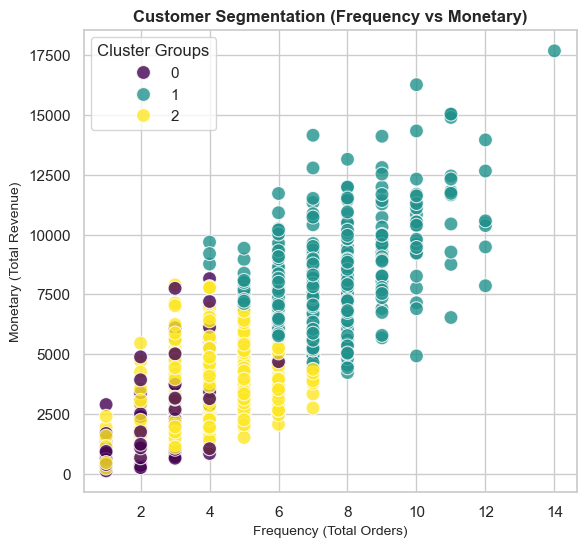

In [40]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=customer_rfm, 
    x='Frequency', 
    y='Monetary', 
    hue='Cluster', 
    palette='viridis', 
    s=100, 
    alpha=0.8m
)
plt.title('Customer Segmentation (Frequency vs Monetary)', fontsize=12, fontweight='bold')
plt.xlabel('Frequency (Total Orders)', fontsize=10)
plt.ylabel('Monetary (Total Revenue)', fontsize=10)
plt.legend(title='Cluster Groups')       

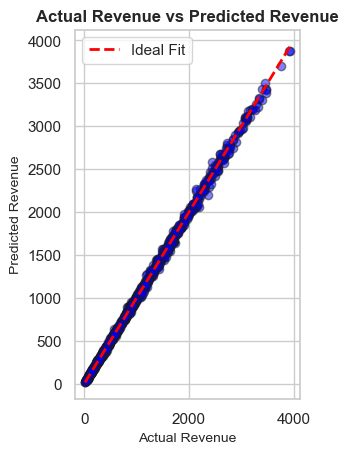

In [41]:
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred, color='blue', alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2, label='Ideal Fit')
plt.title('Actual Revenue vs Predicted Revenue', fontsize=12, fontweight='bold')
plt.xlabel('Actual Revenue', fontsize=10)
plt.ylabel('Predicted Revenue', fontsize=10)
plt.legend()

In [42]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>